# How accurately can population activity predict position?

**Question:** Can place fields estimated from an earlier recording period
predict the animal's position from spikes in a later period?

Train a Bayesian position decoder on the first 2 minutes of a simulated
recording and test it on the final minute. Compare its position estimates
with tracking, examine large errors, and ask whether posterior uncertainty
identifies them. Test positions are used only to evaluate and plot results.

**You will need:** Spike times for the same neurons across training and test
periods, position samples on the spike clock, and the track layout. We
simulate these inputs here, so no data download is needed.

**Estimated time**: 20-25 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb) and
[Recovering simulated place fields](05_simulation_and_validation.ipynb).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial.decoding import BayesianDecoder
from neurospatial.encoding import SpikeTrains
from neurospatial.simulation import linear_track_session

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import OKABE_ITO, apply_style

apply_style(figsize=(12, 4))
COLORS = {"blue": OKABE_ITO[0], "orange": OKABE_ITO[1], "cyan": OKABE_ITO[4]}

## 1. Separate training and test periods

Simulate 20 neurons during repeated runs along a known 100 cm track. Movement,
field placement and spikes use separate random streams. The field parameters
remain fixed throughout, and both periods include repeated track runs. This
tests prediction under stable tuning, not robustness to changes in a recording.

Choose the time split before fitting. The plot shows which samples will be
used for learning place fields and which will be reserved for testing. With
recorded data, separate trials or sessions may be a better choice: randomly
splitting neighboring samples makes training and test data too similar.

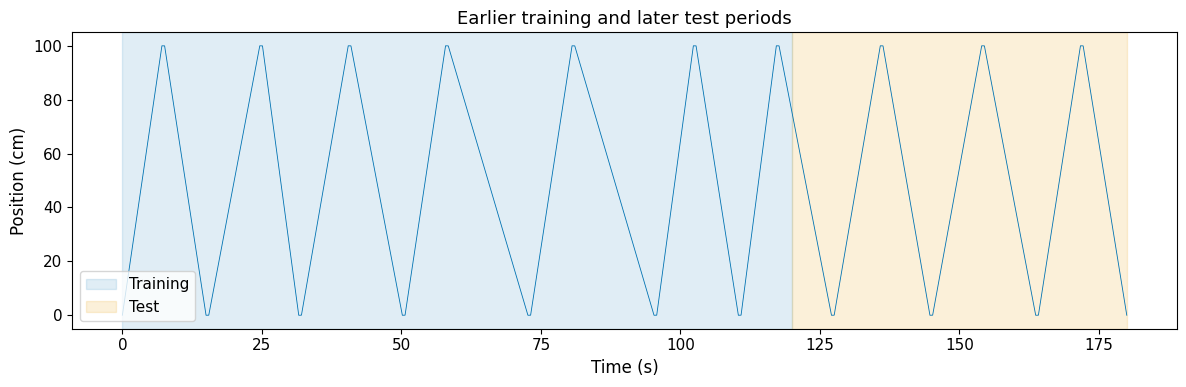

In [2]:
session = linear_track_session(
    duration=180.0,
    track_length=100.0,
    bin_size=2.0,
    n_place_cells=20,
    n_laps=20,
    width=6.0,  # place field standard deviation, cm: our choice
    max_rate=20.0,  # peak rate, Hz: our choice
    seed=2026,
)
env, times, positions = session.env, session.times, session.positions
spikes = SpikeTrains(session.spike_times, unit_ids=100 + session.unit_ids)
train_epochs = (float(times[0]), 120.0)
test_epochs = (120.0, float(times[-1]))
recording_window = (float(times[0]), float(times[-1]))

fig, ax = plt.subplots()
ax.plot(times, positions[:, 0], lw=0.6)
ax.axvspan(*train_epochs, color=COLORS["blue"], alpha=0.12, label="Training")
ax.axvspan(*test_epochs, color=COLORS["orange"], alpha=0.15, label="Test")
ax.set(
    xlabel="Time (s)",
    ylabel="Position (cm)",
    title="Earlier training and later test periods",
)
ax.legend()
fig.tight_layout()
plt.show()

## 2. Learn place fields, then predict position from spikes

The decoder assumes that, at a given position, each neuron's spike count
follows a Poisson distribution independently of the others. Its expected
count in a 100 ms interval is the neuron's firing rate there multiplied by
0.1 s. Combining these count probabilities across neurons gives the relative
evidence for each position. Normalizing over locations with enough training
occupancy gives a posterior distribution over position. We use a uniform
prior over those locations and no movement prior between time bins.

Estimate place fields from training spikes and training occupancy only, with
4 cm smoothing and at least 0.5 s of occupancy per bin. Then decode 100 ms
intervals of test spikes without providing test positions. The maximum a
posteriori (MAP) estimate is the location with the highest posterior
probability; `score` compares it with tracked position.

Keep the same unit identifiers throughout, including units that emit no
spikes in a period. Observing zero spikes from a recorded neuron is evidence;
losing that neuron from the recording is a different situation. `SpikeTrains`
carries the identifiers used to match neurons to their fitted place fields.

In [3]:
# fit returns the fitted decoder; retain that return value.
# All time windows use the recording clock and include their start, not their end.
decoder = BayesianDecoder(
    env, dt=0.1, bandwidth=4.0, min_occupancy=0.5, max_gap=0.5
).fit(
    spikes,
    times,
    positions,
    epochs=train_epochs,
    spike_window=recording_window,
)
result = decoder.predict(
    spikes, times, epochs=test_epochs, spike_window=recording_window
)
test_median_error = decoder.score(
    spikes,
    times,
    positions,
    epochs=test_epochs,
    spike_window=recording_window,
    metric="median_error",
)
print(f"Median position error in the test period: {test_median_error:.2f} cm")
print(f"Unit identifiers used for decoding: {decoder.unit_ids.tolist()}")
print(
    f"Position probabilities: {result.posterior.shape} (100 ms intervals, track bins)"
)

Median position error in the test period: 2.00 cm
Unit identifiers used for decoding: [100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119]
Position probabilities: (599, 51) (100 ms intervals, track bins)


The median test error is 2 cm, about one spatial bin. This describes the
middle of the error distribution. Before calling the decoder accurate, check
where it could make predictions and how large the remaining errors are.

## 3. Did training cover the whole track?

Locations with insufficient training occupancy are excluded from decoding.
They are marked by `decoder.spatial_support` and receive no posterior
probability. A low error would be misleading if it described only a small
part of the track or if many test intervals could not be decoded. Count
included locations, test positions in those locations, and usable estimates.
Here tracking is continuous, so interpolation can locate each test-bin center.

In [4]:
actual_positions = np.column_stack(
    [np.interp(result.times, times, positions[:, axis]) for axis in range(env.n_dims)]
)
actual_bins = env.bin_at(actual_positions)
truth_supported = np.zeros(result.n_time_bins, dtype=bool)
inside = actual_bins >= 0
truth_supported[inside] = decoder.spatial_support[actual_bins[inside]]
decodable = np.any(np.isfinite(result.posterior), axis=1)
errors = result.error_against(times, positions, max_gap=decoder.max_gap)
print(
    f"Track bins with enough training occupancy: "
    f"{decoder.spatial_support.sum()} / {env.n_bins}"
)
print(f"Test positions in those track bins: {truth_supported.mean():.1%}")
print(
    f"Test intervals with position probabilities: {decodable.sum()} / {result.n_time_bins}"
)
print(
    f"Test intervals with measurable error: "
    f"{np.isfinite(errors).sum()} / {result.n_time_bins}"
)
print(f"95th percentile position error: {np.nanpercentile(errors, 95):.2f} cm")
if np.any(~decoder.spatial_support):
    print(
        "Probability assigned to excluded track bins:",
        result.posterior[:, ~decoder.spatial_support].sum(),
    )

Track bins with enough training occupancy: 51 / 51
Test positions in those track bins: 100.0%
Test intervals with position probabilities: 599 / 599
Test intervals with measurable error: 599 / 599
95th percentile position error: 98.00 cm


All 51 track bins have enough training occupancy, all test positions lie in
those bins, and all 599 test intervals have measurable errors. Yet the 95th
percentile error is 98 cm, almost the full track length. Missing spatial
coverage does not explain that large tail. Inspect the learned place fields
and position traces next.

The three example fields below are strongest in the track interior. The
simulated population's field centers are between 20 and 80 cm, so the ends
have weak firing even though the animal spent enough time there.

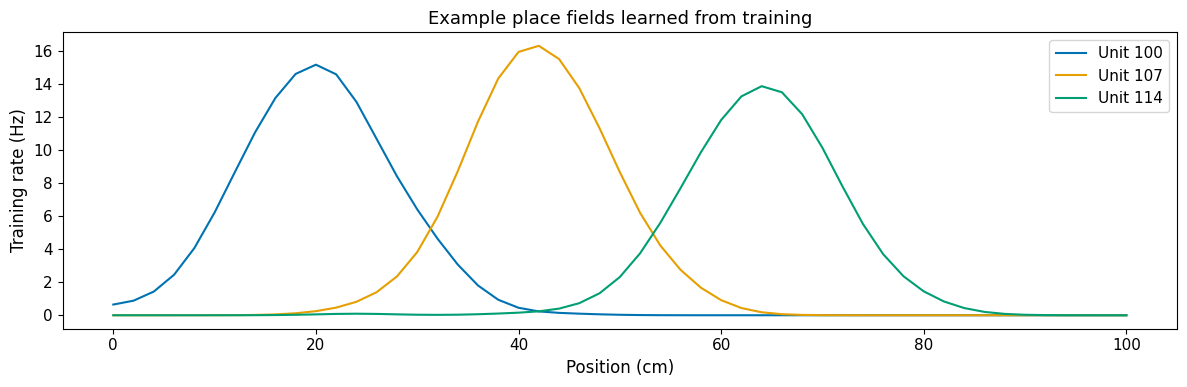

In [5]:
fig, ax = plt.subplots()
for unit_row in (0, 7, 14):
    ax.plot(
        env.bin_centers[:, 0],
        decoder.encoding_models[unit_row],
        label=f"Unit {decoder.unit_ids[unit_row]}",
    )
ax.set(
    xlabel="Position (cm)",
    ylabel="Training rate (Hz)",
    title="Example place fields learned from training",
)
ax.legend()
fig.tight_layout()
plt.show()

## 4. Compare decoded position with tracking

The heatmap shows the posterior at each test time. A narrow bright band means
the model favors a small set of locations. Compare the white MAP estimate
with the cyan tracked position. The plot uses spatial-bin numbers on its
vertical axis; we pass tracking in centimeters and let `result.plot` align it
to that axis. Tracking lines stop at missing observations or long gaps.

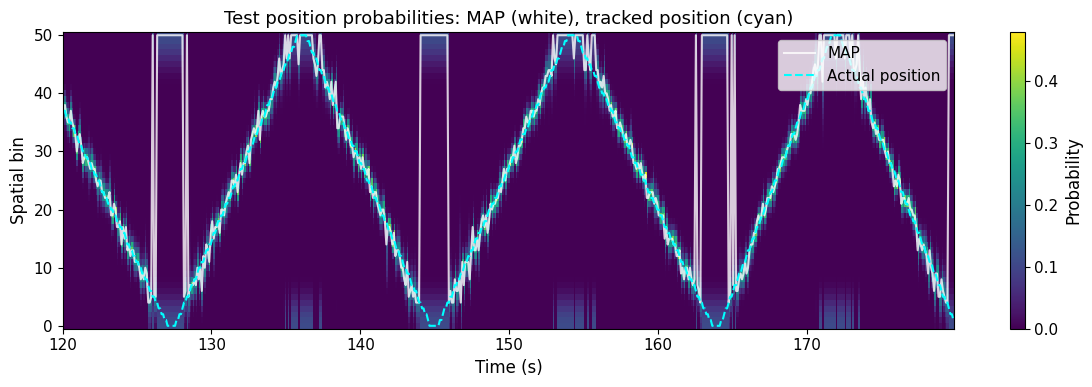

In [6]:
# Supply tracking with its original timestamps for the comparison.
fig, ax = plt.subplots(figsize=(12, 4))
result.plot(
    ax=ax,
    show_map=True,
    colorbar=True,
    true_times=times,
    true_positions=positions,
    max_gap=decoder.max_gap,
)
n_show = min(300, result.n_time_bins)
ax.set_title("Test position probabilities: MAP (white), tracked position (cyan)")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

In this run, the MAP sometimes jumps to the opposite track end while the
animal is near an end. With weak firing at both ends, intervals with no
population spikes can favor the wrong end. The decoder treats time bins
separately, so no movement prior discourages that jump. Enough occupancy to
estimate a field does not guarantee informative spikes for decoding.

The next plot shows the first 30 s of test estimates in centimeters and the
error distribution for the full test period. The median of 2 cm and 95th
percentile of 98 cm describe different parts of that distribution; report
both rather than allowing the median to hide the large errors.

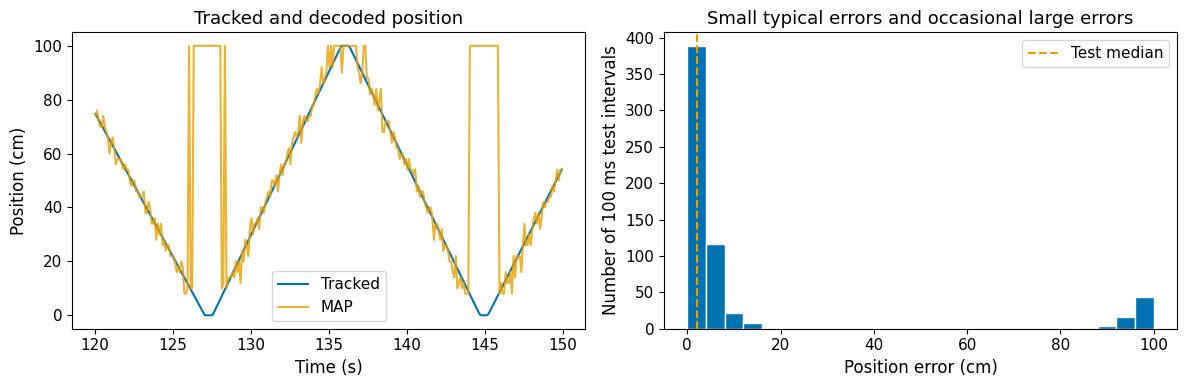

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(result.times[:n_show], actual_positions[:n_show, 0], label="Tracked")
decoded_positions = result.map_position.copy()
decoded_positions[~decodable] = np.nan
axes[0].plot(
    result.times[:n_show],
    decoded_positions[:n_show, 0],
    color=COLORS["orange"],
    alpha=0.8,
    label="MAP",
)
axes[0].set(
    xlabel="Time (s)", ylabel="Position (cm)", title="Tracked and decoded position"
)
axes[0].legend()
finite_errors = errors[np.isfinite(errors)]
axes[1].hist(finite_errors, bins=25, edgecolor="white")
axes[1].axvline(test_median_error, color=COLORS["orange"], ls="--", label="Test median")
axes[1].set(
    xlabel="Position error (cm)",
    ylabel="Number of 100 ms test intervals",
    title="Small typical errors and occasional large errors",
)
axes[1].legend()
fig.tight_layout()
plt.show()

## 5. Does posterior uncertainty identify decoding errors?

Posterior entropy measures how spread out the position probabilities are.
Low entropy means the fitted model strongly favors fewer positions; high
entropy means it spreads probability more broadly. Each point below is one
test interval. Compare the model's uncertainty with its measured error.

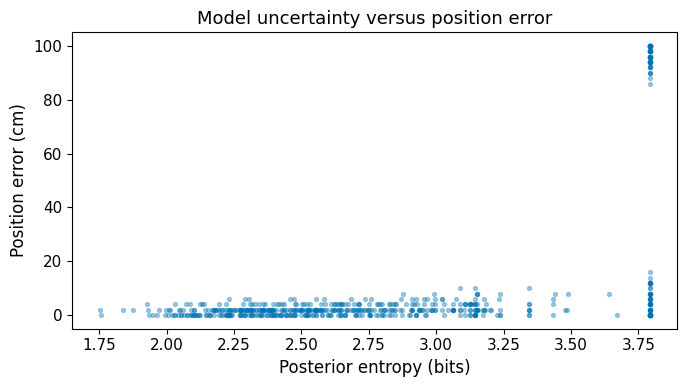

In [8]:
entropy = result.posterior_entropy
fig, ax = plt.subplots(figsize=(7, 4))
valid = np.isfinite(entropy) & np.isfinite(errors)
ax.scatter(entropy[valid], errors[valid], s=8, alpha=0.35)
ax.set(
    xlabel="Posterior entropy (bits)",
    ylabel="Position error (cm)",
    title="Model uncertainty versus position error",
)
fig.tight_layout()
plt.show()

Entropy is not a calibrated probability that an estimate is correct. In
recorded populations, correlated firing or changing place fields can violate
the model's assumptions and produce confident errors. This simulation, with
stable tuning and independently generated spikes, does not test those effects.

## Use your own recording

Supply spike times in seconds, tracked positions in the environment's units,
and stable unit identifiers. Keep empty spike trains for neurons that were
recorded but silent. Use actual acquisition windows, and choose a maximum
tracking gap appropriate to your sampling. Both the position overlay and
`error_against` use `max_gap` to avoid interpolating through missing tracking;
decoding time bins also stop at those gaps.

Choose smoothing, minimum occupancy and decoding bin width using training
and separate validation periods. Keep the test period for the final report.
Report spatial coverage, the fraction of measurable errors, typical error
and large errors. Assess variation across independent trials or sessions,
rather than treating neighboring 100 ms bins as independent repetitions.
On a branching maze, use geodesic error so that distances follow valid paths.

If you already have population rate maps, `BayesianDecoder.from_rates` reuses
them while keeping locations with too little occupancy excluded. For long
recordings, `predict_summary` returns estimates and entropy without storing
the full posterior. See [visualization](08_visualization.ipynb) to animate
position probabilities.